In [14]:
# useful packages
from astropy.io import fits
import os
import re
import glob

### How to read a fits header

This is what a good fits header looks like: 

In [7]:
hdr = fits.getheader('../data/WASP36b/Dark_Flats_02172025.2025-02-17.0080.fits')
hdr

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 1117 / length of data axis 1                          
NAXIS2  =                  844 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
BZERO   =                32768 / offset data range to that of unsigned short    
BSCALE  =                    1 / default scaling factor                         
ROWORDER= 'TOP-DOWN'           / Row Order                                      
INSTRUME= 'SBIG CCD'           / Camera Name                                    
TELESCOP= 'Telescope Simulator' / Telescope name                                
EXPTIME =         4.000000E-01 / Total Exposure Time (s)                        
DARKTIME=         4.000000E-

This is what the bad fits headers look like: 

In [12]:
bhdr = fits.getheader('../data/2026-10-15/ST_TRI.2026-10-15.0326.fits')
bhdr

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1117                                                  
NAXIS2  =                  844                                                  
EXTEND  =                    T                                                  
BSCALE  =                    1                                                  
BZERO   =                32768                                                  
DOME_PA = '58.91   '           / Dome position angle                            
LST     = '21:49:52'           / Local Siderial Time                            
HA      = '19:08:26'           / Hour Angle                                     
RA      = '02:41:25'           / Telescope RA                                   
DEC     = '35:43:15'        

In [32]:
# Here's what a dark frame from the bad data set looks like
bdhdr = fits.getheader('../data/2026-10-15/Darks.2026-10-15.0390.fits')
bdhdr

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1117                                                  
NAXIS2  =                  844                                                  
EXTEND  =                    T                                                  
BSCALE  =                    1                                                  
BZERO   =                32768                                                  
LST     = '0.0741  '                                                            
HA      = '21.3952 '                                                            
RA      = '02:40:45'           / Telescope RA                                   
DEC     = '35:37:22'           / Telescope Dec                                  
CENTRDX = '40.54   '        

For `sort_observations.py`, the pipeline requires the following keywords be in the fits headers: `FRAME`, `EXPTIME`, `FILTER`, `OBJECT`

These are missing 2/4 of those and `DATE-OBS` which will be critical for some observations


So we have filter theoretically: this dataset only observed in one filter so we'll need to make sure its not set to a single filter for observations with multiple filters.

The `OBJECT` keyword in this dataset and the file names themseleves have the frame type in them luckily, so we can add the `FRAME` key too the header and populate those based on the info we have.

The frame types as read by the pipeline need to be written exactly as one of the following: 'Bias', 'Dark', 'Flat', 'Light' so we can search for the files in a dataset by the filenames or OBJECT keyword containing the string 'Darks', but we'll need to change how its entered to the `FRAME` keyword

Here's how:


In [9]:
fits.setval("/Users/bencapistrant/Downloads/Darks.2026-10-15.0390 copy.fits", "FRAME", value="Dark", comment="Filter name")
fits.getheader("/Users/bencapistrant/Downloads/Darks.2026-10-15.0390 copy.fits")

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1117                                                  
NAXIS2  =                  844                                                  
EXTEND  =                    T                                                  
BSCALE  =                    1                                                  
BZERO   =                32768                                                  
LST     = '0.0741  '                                                            
HA      = '21.3952 '                                                            
RA      = '02:40:45'           / Telescope RA                                   
DEC     = '35:37:22'           / Telescope Dec                                  
CENTRDX = '40.54   '        

So you could loop through based on the file name and add these, but not all of them may have that included in the name, so since we have the logbook anyways we can use frame numbers to update all of the keywords at once

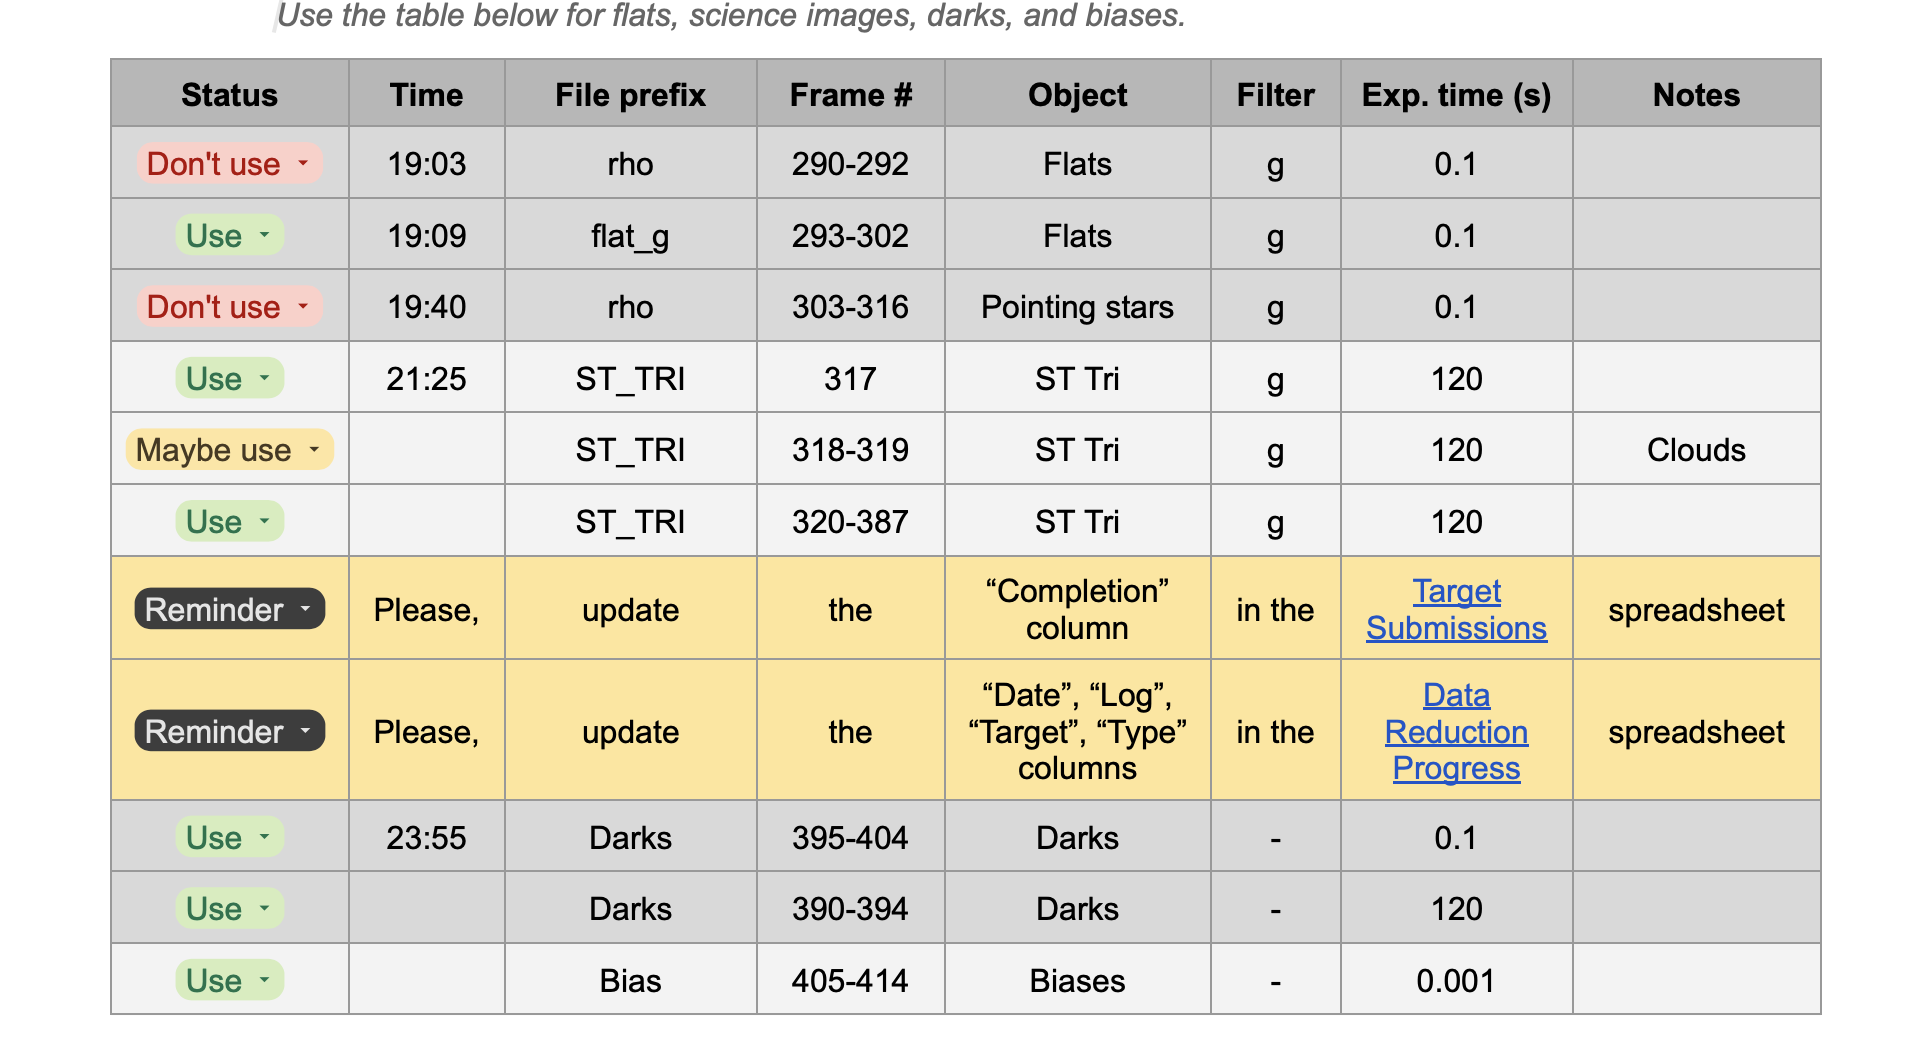

In [ ]:
# This is just to display the logbook from this night, refer to the google drive for this information
from IPython.display import Image, display

display(Image(filename='/Users/bencapistrant/Desktop/sample_logbook.png'))

In [28]:
# Checking out the filename structure, we can see how the frame number is at the end of the file name.
data_dir = glob.glob('../data/2026-10-15/*.fits')
data_dir[0:10]

['../data/2026-10-15/rho.2026-10-15.0303.fits',
 '../data/2026-10-15/ST_TRI.2026-10-15.0347.fits',
 '../data/2026-10-15/ST_TRI.2026-10-15.0351.fits',
 '../data/2026-10-15/rho.2026-10-15.0315.fits',
 '../data/2026-10-15/ST_TRI.2026-10-15.0384.fits',
 '../data/2026-10-15/flat_g.2026-10-15.0293.fits',
 '../data/2026-10-15/ST_TRI.2026-10-15.0371.fits',
 '../data/2026-10-15/ST_TRI.2026-10-15.0326.fits',
 '../data/2026-10-15/ST_TRI.2026-10-15.0330.fits',
 '../data/2026-10-15/ST_TRI.2026-10-15.0367.fits']

In [33]:
# Going to structure the logbook as an array to guide the loop,
# going to label any frames that say don't use as 'unknown' so that they're not included in the calibrations

# This dataset only had one filter, you'll need to separate by filter if there were multiple

# (first frame, last frame, FRAME, OBJECT, FILTER, EXPTIME) copied from the logbook.
logbook = [
    (290, 292, "Unknown", "Unknown", None, None),   # bad flats, don't use
    (293, 302, "Flat",    "Flats",   "G",  0.1),
    (303, 316, "Unknown", "Unknown", None, None),   # pointing stars, don't use
    (317, 387, "Light",   "ST Tri",  "G",  120.0),  # includes 318-319 ("maybe use", clouds)
    (390, 394, "Dark",    "Darks",   "-",  120.0),
    (395, 404, "Dark",    "Darks",   "-",  0.1),
    (405, 414, "Bias",    "Biases",  "-",  0.001),
]

In [34]:
data_path = '../data/2026-10-15/'

def frame_number(path):
    # Darks.2026-10-16.0392.fits -> 392 (frame number is last group of digits before .fits)
    return int(re.findall(r"\d+", os.path.basename(path)[:-5])[-1])

def lookup(n):
    for first, last, frame, obj, filt, exptime in logbook:
            if first <= n <= last:
                return frame, obj, filt, exptime
    return "Unknown", "Unknown", None, None


In [35]:
# Just to preview the changes before anything is written

files = sorted(data_dir)

for f in files: 
    print(os.path.basename(f), frame_number(f), lookup(frame_number(f)))


Bias.2026-10-16.0405.fits 405 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0406.fits 406 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0407.fits 407 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0408.fits 408 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0409.fits 409 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0410.fits 410 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0411.fits 411 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0412.fits 412 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0413.fits 413 ('Bias', 'Biases', '-', 0.001)
Bias.2026-10-16.0414.fits 414 ('Bias', 'Biases', '-', 0.001)
Darks.2026-10-15.0390.fits 390 ('Dark', 'Darks', '-', 120.0)
Darks.2026-10-15.0391.fits 391 ('Dark', 'Darks', '-', 120.0)
Darks.2026-10-16.0392.fits 392 ('Dark', 'Darks', '-', 120.0)
Darks.2026-10-16.0393.fits 393 ('Dark', 'Darks', '-', 120.0)
Darks.2026-10-16.0394.fits 394 ('Dark', 'Darks', '-', 120.0)
Darks.2026-10-16.0395.fits 395 ('Dark', 'Darks', '-', 0.1)
Darks.2026-10-16.0396.fits

In [ ]:
# Write the actual headers 
for f in files:
    frame, obj, filt, exptime = lookup(frame_number(f))
    with fits.open(f, mode="update") as hdul:
        hdr = hdul[0].header
        hdr["FRAME"] = (frame, "Frame type")
        hdr["OBJECT"] = (obj, "Target name")
        if filt is not None:
            hdr["FILTER"] = (filt, "Filter name")
        if exptime is not None:
            hdr["EXPTIME"] = (exptime, "Exposure time (s)")


In [45]:
# Check our results
check_hdr = fits.getheader(data_dir[1])
check_hdr

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1117                                                  
NAXIS2  =                  844                                                  
EXTEND  =                    T                                                  
BSCALE  =                    1                                                  
BZERO   =                32768                                                  
LST     = '22.5574 '                                                            
HA      = '19.8704 '                                                            
RA      = '02:41:12'           / Telescope RA                                   
DEC     = '35:42:01'           / Telescope Dec                                  
CENTRDX = '394.06  '        

Hooray, now sort_observations should be able to run. However there's one more thing we can add once we've added this info to the header as long as your data is newly downloaded from the computer (which this sample dataset is not currently)

### Writing observation times

I'm going to try adding the observation dates to the fits headers based on the file creation date in the RHO computers. The file creation date gets re-written any time its copied or moved, so doing this on folders from the teams won't work. 

Because the file creation date is at the end of the observation, and the `DATE-OBS` keyword refers to the observation start time, we need to subtract the frame's exposure time that you just added to the `EXPTIME` keyword to get that start time.

I'll save those keywords as `SAVETIME` so that any that were written incorrectly, copied or moved don't have a large negative impact on the final `DATE-OBS` times. There may still be a slight offset due to any readout time, but at least that should be a constant offset for all the observations.

In [51]:
#Testing, this is how I'll write SAVETIME, but this is from a teams dataset 

from datetime import datetime, timezone
st = os.stat(data_path[0])


save_time = datetime.fromtimestamp(st.st_ctime, tz=timezone.utc).strftime("%Y-%m-%dT%H:%M:%S")
save_time

'2026-11-06T17:08:51'

In [ ]:
from datetime import datetime, timedelta
(datetime.strptime(save_time, "%Y-%m-%dT%H:%M:%S")-timedelta(seconds=float(check_hdr["EXPTIME"]))).strftime("%Y-%m-%dT%H:%M:%S")



'2026-11-06T17:06:51'

In [53]:
# This would be how we write those to the headers once they have SAVETIME there

# for f in files:
#     with fits.open(f, mode="update") as hdul:
#         hdr = hdul[0].header
#         saved = datetime.strptime(hdr["SAVETIME"], "%Y-%m-%dT%H:%M:%S")
#         start = saved - timedelta(seconds=float(hdr["EXPTIME"]))
#         hdr["DATE-OBS"] = (start.strftime("%Y-%m-%dT%H:%M:%S"), "UTC, start of exposure")
